# 13. Modal Expansion Analysis: Bloch Mode & Plane-Wave Coupling Amplitudes

## Physical Motivation & Learning Objectives
Understanding how energy distributes between modal channels clarifies resonance excitation. In this tutorial:
1. We compute Bloch mode excitation amplitudes (`plotting.BM_amplitudes`).
2. We compute plane-wave diffraction order distributions (`plotting.PW_amplitudes`).
3. We evaluate evanescent field decay figures of merit (`plotting.evanescent_merit`).


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Grating Setup


In [2]:
wavelengths = np.linspace(600, 900, 4)
period = 760.0  # nm

light_list = [objects.Light(wl, max_order_PWs=2, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(1.45), world_1d=True, loss=False)

grating = objects.NanoStruct(
    '1D_array', period, int(round(0.75 * period)),
    height_nm=2900.0,
    background=materials.Material(1.46),
    inclusion_a=materials.Material(3.61),
    loss=True, lc_bkg=0.01, plt_msh=False
)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_grt = grating.calc_modes(light, num_BMs=20)
    stk = Stack((sim_sub, sim_grt, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

stacks_list = [simulate_stack(light) for light in light_list]


## Modal Amplitudes & Evanescent Merit Analysis


<ipython-input-1-551ea2524e89>:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
<ipython-input-1-551ea2524e89>:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
<ipython-input-1-551ea2524e89>:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


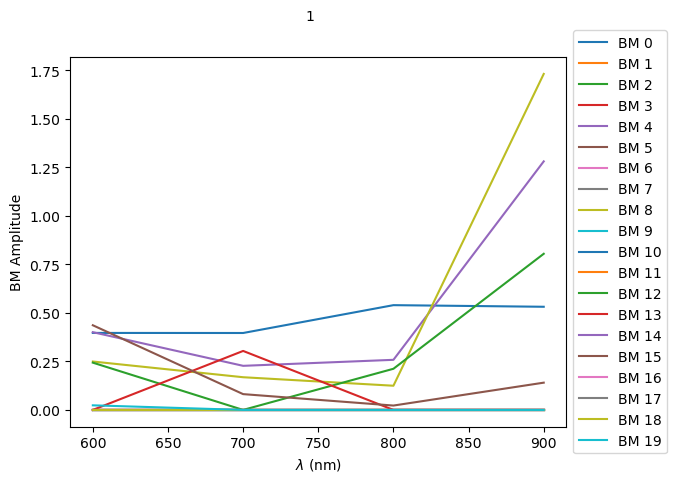

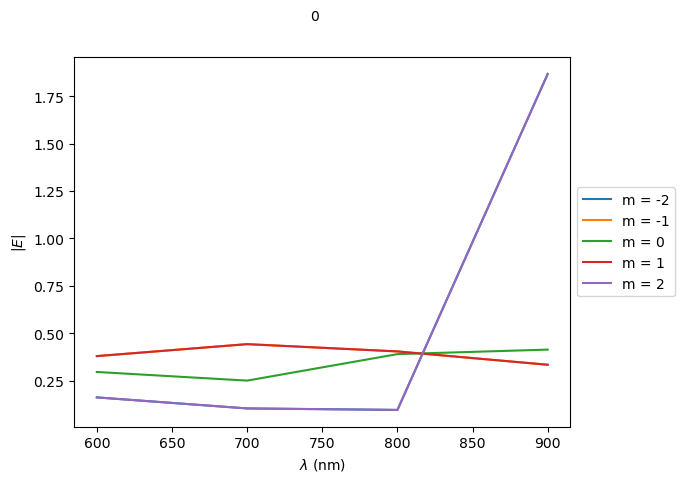

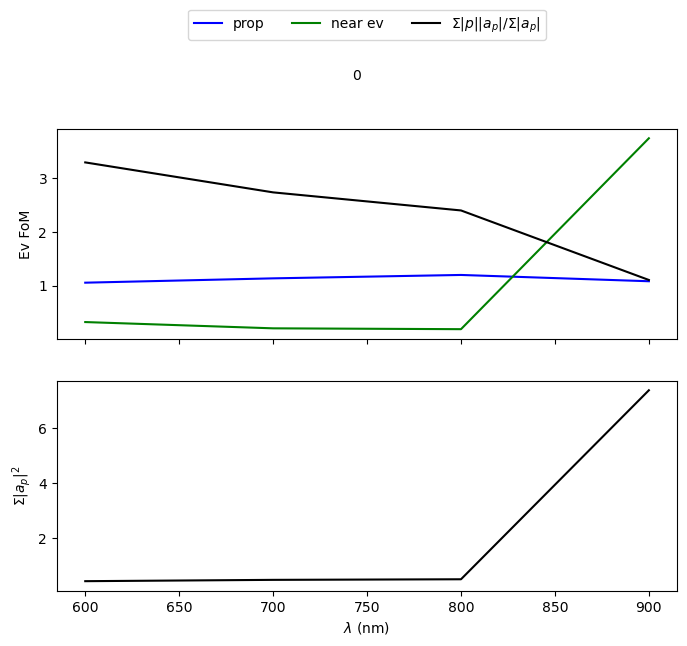

In [3]:
figs_bm = plotting.BM_amplitudes(stacks_list, save_pdf=False)
plt.show()

figs_pw = plotting.PW_amplitudes(stacks_list, save_pdf=False)
plt.show()

figs_ev = plotting.evanescent_merit(stacks_list, save_pdf=False)
plt.show()


## Physical Interpretation
- Amplitudes identify which Bloch modes couple directly to incident radiation and carry net Poynting flux.
- Evanescent decay figures of merit quantify the penetration depth of near-field orders into neighboring layers.
